
# FraudShield AI
## Exploratory Data Analysis and Preprocessing

### Objective
- Load the merged IEEE-CIS dataset.
- Understand the dataset structure and fraud distribution.
- Investigate missing values and transaction patterns.
- Identify data quality issues and potential leakage.
- Prepare the data for a reliable machine-learning baseline.


In [1]:

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

PROJECT_ROOT = Path(r"D:\FraudShield")
DATA_FILE = PROJECT_ROOT / "data" / "processed" / "train_merged.parquet"
REPORT_DIR = PROJECT_ROOT / "reports"

REPORT_DIR.mkdir(parents=True, exist_ok=True)

if not DATA_FILE.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_FILE}")

df = pd.read_parquet(DATA_FILE)

print("Dataset loaded successfully!")
print(f"Shape: {df.shape}")
print(f"Memory usage: {df.memory_usage(deep=True).sum() / (1024**2):.2f} MB")

display(df.head())


Dataset loaded successfully!
Shape: (590540, 434)
Memory usage: 2427.43 MB


,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,...,None,NaN,None,None,None,None,None,None,None,None
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,...,None,NaN,None,None,None,None,None,None,None,None
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,...,None,NaN,None,None,None,None,None,None,None,None
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,...,None,NaN,None,None,None,None,None,None,None,None
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,...,samsung browser 6.2,32.0,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M


In [2]:

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.value_counts().to_frame("column_count"))

print("\nSample data:")
display(df.sample(min(5, len(df)), random_state=42).T)


Number of rows: 590540
Number of columns: 434

Column names:
['TransactionID', 'isFraud', 'TransactionDT', 'TransactionAmt', 'ProductCD', 'card1', 'card2', 'card3', 'card4', 'card5', 'card6', 'addr1', 'addr2', 'dist1', 'dist2', 'P_emaildomain', 'R_emaildomain', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9', 'C10', 'C11', 'C12', 'C13', 'C14', 'D1', 'D2', 'D3', 'D4', 'D5', 'D6', 'D7', 'D8', 'D9', 'D10', 'D11', 'D12', 'D13', 'D14', 'D15', 'M1', 'M2', 'M3', 'M4', 'M5', 'M6', 'M7', 'M8', 'M9', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'V29', 'V30', 'V31', 'V32', 'V33', 'V34', 'V35', 'V36', 'V37', 'V38', 'V39', 'V40', 'V41', 'V42', 'V43', 'V44', 'V45', 'V46', 'V47', 'V48', 'V49', 'V50', 'V51', 'V52', 'V53', 'V54', 'V55', 'V56', 'V57', 'V58', 'V59', 'V60', 'V61', 'V62', 'V63', 'V64', 'V65', 'V66', 'V67', 'V68', 'V69', 'V70', 'V71', 'V72', 'V73

,column_count
float64,399
object,31
int64,4



Sample data:


,470624,565820,284083,239689,281855
TransactionID,3457624,3552820,3271083,3226689,3268855
isFraud,0,0,0,0,0
TransactionDT,12153579,15005886,6970178,5673658,6886780
TransactionAmt,724.0,108.5,47.95,100.599,107.95
ProductCD,W,W,W,C,W
...,...,...,...,...,...
id_36,None,None,None,None,None
id_37,None,None,None,None,None
id_38,None,None,None,None,None
DeviceType,None,None,None,None,None


,count,percentage
Legitimate (0),569877,96.501
Fraud (1),20663,3.499


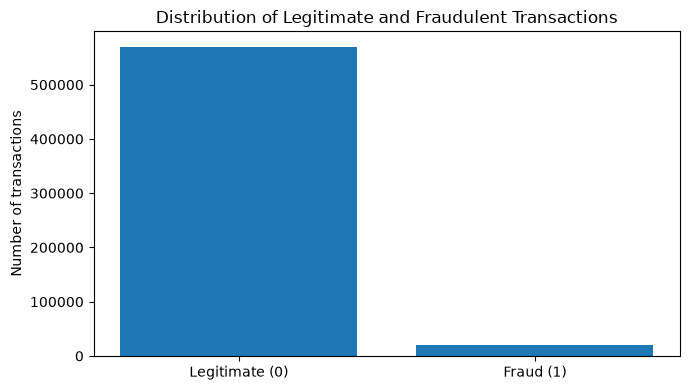

Fraud rate: 3.4990%


In [3]:

target_counts = df["isFraud"].value_counts().sort_index()

target_summary = pd.DataFrame({
    "count": target_counts,
    "percentage": target_counts / len(df) * 100
})

target_summary.index = ["Legitimate (0)", "Fraud (1)"]
display(target_summary.round(3))

plt.figure(figsize=(7, 4))
plt.bar(target_summary.index, target_summary["count"])
plt.title("Distribution of Legitimate and Fraudulent Transactions")
plt.ylabel("Number of transactions")
plt.tight_layout()
plt.show()

print(f"Fraud rate: {df['isFraud'].mean() * 100:.4f}%")


In [4]:

missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percentage": df.isna().mean() * 100
})

missing = missing.sort_values("missing_percentage", ascending=False)

display(missing.head(30).round(2))

missing.to_csv(REPORT_DIR / "merged_missingness.csv")

print("Missingness report saved to reports/merged_missingness.csv")


,missing_count,missing_percentage
id_24,585793,99.20
id_25,585408,99.13
id_07,585385,99.13
id_08,585385,99.13
id_21,585381,99.13
id_26,585377,99.13
id_27,585371,99.12
id_23,585371,99.12
id_22,585371,99.12
dist2,552913,93.63


Missingness report saved to reports/merged_missingness.csv


,count,mean,median,std,min,max
Legitimate,569877,134.51,68.5,239.40,0.25,31937.39
Fraud,20663,149.24,75.0,232.21,0.29,5191.00


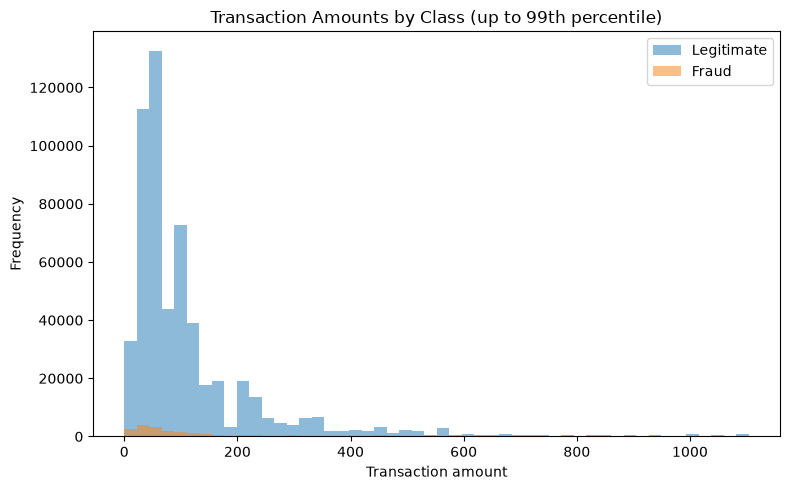

In [5]:

amount_summary = df.groupby("isFraud")["TransactionAmt"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

amount_summary.index = ["Legitimate", "Fraud"]
display(amount_summary.round(2))

# Clip the plot at the 99th percentile so extreme amounts don't dominate it.
upper_limit = df["TransactionAmt"].quantile(0.99)

plt.figure(figsize=(8, 5))

for label, name in [(0, "Legitimate"), (1, "Fraud")]:
    values = df.loc[df["isFraud"] == label, "TransactionAmt"]
    values = values[values <= upper_limit]
    plt.hist(values, bins=50, alpha=0.5, label=name)

plt.xlabel("Transaction amount")
plt.ylabel("Frequency")
plt.title("Transaction Amounts by Class (up to 99th percentile)")
plt.legend()
plt.tight_layout()
plt.show()


,transaction_count,fraud_rate,fraud_rate_percent
ProductCD,,,
W,439670,0.020,2.040
C,68519,0.117,11.687
R,37699,0.038,3.783
H,33024,0.048,4.766
S,11628,0.059,5.900


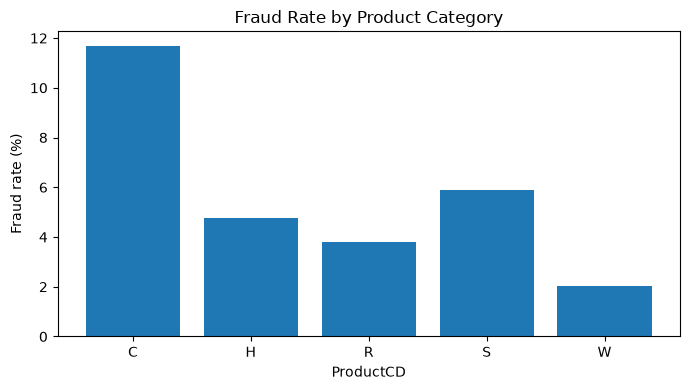

In [6]:

product_summary = (
    df.groupby("ProductCD", dropna=False)["isFraud"]
      .agg(transaction_count="count", fraud_rate="mean")
)

product_summary["fraud_rate_percent"] = product_summary["fraud_rate"] * 100

display(product_summary.sort_values("transaction_count", ascending=False).round(3))

plt.figure(figsize=(7, 4))
plt.bar(
    product_summary.index.astype(str),
    product_summary["fraud_rate_percent"]
)
plt.title("Fraud Rate by Product Category")
plt.xlabel("ProductCD")
plt.ylabel("Fraud rate (%)")
plt.tight_layout()
plt.show()


In [7]:

eda_summary = {
    "rows": int(df.shape[0]),
    "columns": int(df.shape[1]),
    "fraud_count": int(df["isFraud"].sum()),
    "legitimate_count": int((df["isFraud"] == 0).sum()),
    "fraud_rate_percent": float(df["isFraud"].mean() * 100),
    "columns_with_missing_values": int((df.isna().sum() > 0).sum()),
    "identity_match_rate_percent": float(
        df[[c for c in df.columns if c.startswith("id_") or c in ["DeviceType", "DeviceInfo"]]]
        .notna()
        .any(axis=1)
        .mean() * 100
    )
}

display(pd.Series(eda_summary, name="value").to_frame())

pd.Series(eda_summary).to_json(
    REPORT_DIR / "eda_summary.json",
    indent=2
)

print("EDA summary saved.")


,value
rows,590540.000000
columns,434.000000
fraud_count,20663.000000
legitimate_count,569877.000000
fraud_rate_percent,3.499001
columns_with_missing_values,414.000000
identity_match_rate_percent,24.423917


EDA summary saved.
